# 5. Butane: Rotation Energy Profiles

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4/blob/main/book/05-RotationProfiles/051-RotationProfiles.ipynb)
:::

One of the easiest chemical **transformations** to model and explore in computational chemistry is **conformational** changes. We will start with potential energy profiles for **rotation**. We will build butane using a *Z-matrix* in *Python* and then hand it to *Psi4* as an optimization calculation.

No more symmetry (for now). If we want to rotate molecules around bonds, the symmetry will be **changing** with the rotation. Do consider that symmetry saved a lot of computational effort and should be considered carefully when using expensive methods. We will downgrade our **method** for optimizations to HF/3-21G.

## Learning Goals

In this exercise, we will accomplish the following…

1.	**Build** butane with a *Z-matrix* and **identify** the internal coordinate that describes rotation around the central C&ndash;C bond.
2.	**Freeze a coordinate** in a series of internal coordinates.
3.	**Change** the frozen coordinate and obtain the optimized structure and energy within that limitation.
4.	Learn **how to use** the optimization **history** and the output files to **extract data** quickly. In the [next section](052-Workflow.ipynb) we will use a *Python* loop to run a large series of calculations with different values for the frozen coordinate.
5.	With these methods we will create a **rotational energy profile** around a given bond in an alkane.

In [17]:
####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Install packages only if needed
# Google Colab does not include every Python package
#
# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
try:                  # if the package exists import it, otherwise install it
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4
    import psi4

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Plot style sheets from the book's GitHub repository
if IN_COLAB and not Path("styles/tufte.mplstyle").exists():
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4/main/styles/tufte.mplstyle
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4/main/styles/S2_classic2.mplstyle

if IN_COLAB:
    plt.style.use("styles/tufte.mplstyle")
else:
    plt.style.use("../../styles/tufte.mplstyle")

## Setting Up the Notebook

As in the previous chapters, the hidden **first code cell** imports *Psi4*, *py3Dmol*, *NumPy*, *pandas* and *Matplotlib* and applies the plot **style sheet**. You will see it when you open the notebook in *Jupyter*, *Visual Studio Code* or *Google Colab*.

```{admonition} Running this notebook in Google Colab
:class: dropdown
The first code cell checks whether the notebook is running in *Google Colab*. If it is, the cell **installs** *Psi4* for you. *Colab* does not come with *conda*, so the cell first installs it using a package called *condacolab*. This **restarts** the *Colab* session. When it has restarted, simply **run the first cell again**. It will then install *Psi4* with *conda* (*Psi4* cannot be installed with *pip*), install *py3Dmol* with *pip*, and download the plot style sheets from the book's *GitHub* repository. This takes a few minutes, and you must do it every time you start a new *Colab* session. On your own computer, the cell just imports the packages.
```

Next, we tell *Psi4* how much of the computer it may use, and set the options that we will need in this chapter.

In [18]:
psi4.set_memory("4 GB")
psi4.set_num_threads(4)

psi4.set_options({"scf_type": "pk"})

| Line | Notes |
| :---- | :---- |
| `"scf_type": "pk"` | Calculate the electron repulsion integrals **exactly**, as in the previous chapters. |

We will add the option that **freezes** a coordinate later in the chapter, when we need it.

### Some Helpful Tools

We will reuse the functions from the previous chapters, including `dihedral()` for measuring **torsion** angles. In the webbook, click on the code section to expand it. Run the cell below once.

In [19]:
def show_molecule(mol):
    view = py3Dmol.view(width=400, height=300)
    view.addModel(mol.save_string_xyz_file(), "xyz")
    view.setStyle({"stick": {}, "sphere": {"scale": 0.25}})
    view.setBackgroundColor("#f2f2f2")
    view.zoomTo()
    view.show()

def bond_length(mol, i, j):
    xyz = mol.geometry().np * psi4.constants.bohr2angstroms
    return np.linalg.norm(xyz[i] - xyz[j])

def bond_angle(mol, i, j, k):
    xyz = mol.geometry().np
    a = xyz[i] - xyz[j]
    b = xyz[k] - xyz[j]
    cos_angle = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
    return np.degrees(np.arccos(cos_angle))

def dihedral(mol, i, j, k, l):
    xyz = mol.geometry().np
    b1 = xyz[j] - xyz[i]
    b2 = xyz[k] - xyz[j]
    b3 = xyz[l] - xyz[k]
    n1 = np.cross(b1, b2)
    n2 = np.cross(b2, b3)
    x = np.dot(n1, n2)
    y = np.dot(np.cross(n1, n2), b2) / np.linalg.norm(b2)
    return np.degrees(np.arctan2(y, x))

def plot_history(history, title):
    energies = np.array(history["energy"])
    delta_E = (energies - energies[-1]) * psi4.constants.hartree2kJmol
    steps = np.arange(1, len(energies) + 1)

    fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4))
    ax.plot(steps, delta_E, color="black", linewidth=0.7, marker="o",
            markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5)
    ax.set_xticks(steps)
    ax.set_xlabel("Optimization step")
    ax.set_ylabel(r"$E - E_{final}$ (kJ/mol)")
    ax.set_title(title)
    plt.show()

def search_file(filename, text):
    with open(filename) as f:
        for number, line in enumerate(f, start=1):
            if text.lower() in line.lower():
                print(f"{number:6d}: {line.rstrip()}")

| Function | What it does |
| :---- | :---- |
| `show_molecule(mol)` | Draws the molecule with *py3Dmol*. |
| `bond_length(mol, i, j)` | The distance between atoms `i` and `j` in **&Aring;ngstroms**. |
| `bond_angle(mol, i, j, k)` | The angle `i`&ndash;`j`&ndash;`k` in **degrees**, with `j` in the middle. |
| `dihedral(mol, i, j, k, l)` | The **torsion** (dihedral) angle `i`&ndash;`j`&ndash;`k`&ndash;`l` in degrees, looking down the `j`&ndash;`k` bond. |
| `plot_history(history, title)` | **Plots** the energy at each step of an optimization, relative to the final energy, in *kJ/mol*. |
| `search_file(filename, text)` | **Prints** every line of a text file that contains `text`, with its line number. |

```{note}
*Python* counts atoms from **zero**. The *Z-matrix*, and the *Psi4* options that freeze coordinates, count from **one**. We will need both in this chapter. Keep your wits about you.
```

## Building Butane

In the *GAMESS* version of this book, we built butane by clicking atoms together in a molecule builder program and let it write the input file for us. We will use **internal coordinates** that describe each atom's relationship to another atom or atoms. We could use an *xyz* coordinate system but that is a block of numbers that can be difficult to interpret. Internal coordinates make more sense when examined by the human eye and allow for greater control in setting up initial **geometries** and bond angles. The internal coordinate system that we will use is the *Z-matrix*.

### The *Z-Matrix*

The *Z-matrix* for butane is composed of 14 lines for the 14 atoms. Here is the *Z-matrix* that was produced by the builder program for the *GAMESS* book, with one small change that we will discuss below.

```text
C
C   1    1.54000
C   2    1.54000  1  109.4712
C   1    1.54000  2  109.4712  3  180.0000
H   1    1.14000  2  109.4712  4 -120.0000
H   1    1.14000  5  109.4712  2  120.0000
H   2    1.14000  1  109.4712  3 -120.0000
H   2    1.14000  7  109.4712  1  120.0000
H   3    1.14000  2  109.4712  8   60.0000
H   3    1.14000  9  109.4712  2  120.0000
H   3    1.14000  9  109.4712  10 120.0000
H   4    1.14000  1  109.4712  6   60.0000
H   4    1.14000  12 109.4712  1  120.0000
H   4    1.14000  12 109.4712  13 120.0000
```

Let us build the *Z-matrix* **line by line** using the example above.

The **first** atom in the matrix is a carbon and will be atom \#1 in the system.

```text
C
```

The **second** atom is also a carbon and will be atom \#2. It is 1.54 &Aring; away from atom \#1. For two atoms, all we need to define the molecule is that single **bond length** value.

```text
C
C   1    1.54000
```

The **third** line is atom \#3. In this matrix it describes the third carbon atom in butane. It will be 1.54 &Aring; from atom \#2 but now the distance no longer completely describes its position in the system. We know the **distance** from atom \#2 to this atom \#3, but we also now need a bond **angle** between atoms \#3, 2 and 1. In *sp<sup>3</sup>* carbons that angle is 109.5&deg; (120&deg; for *sp<sup>2</sup>* and 180&deg; for *sp*).

```text
C
C   1    1.54000
C   2    1.54000  1  109.4712
```

The **fourth** line describes the fourth carbon atom, atom \#4. It is 1.54 &Aring; from atom \#1. The bond angle between atoms \#4, 1, and 2 is 109.5&deg;. However, this is not enough information for four atoms. Three atoms are in a **plane**, by definition. Distance and angle will locate them all. However, a fourth atom is potentially outside of the plane of the first three. We now will add the angle to that fourth atom relative to the plane of the first three. This is a **dihedral angle**. In the case of our structure, the angle of the bond between atoms \#4 and \#1 relative to the plane of atoms \#1, 2 and 3 is 180&deg;. That is the same as saying that the plane described by \#1,2,3 is 180&deg; relative to the plane described by \#4,1,2.

This fourth line is very important. This dihedral angle is the **bond rotation** along the central C&ndash;C bond. This is the angle we will be using to rotate the centre bond of butane. {numref}`fig5-2A` shows the *Z-matrix* so far.

```text
C
C   1    1.54000
C   2    1.54000  1  109.4712
C   1    1.54000  2  109.4712  3  180.0000
```

```{figure} ../../images/profiles_Picture2A.png
---
width: 450px
name: fig5-2A
---
*The first four lines of the Z-matrix are applied.*
```

By the **last line**, we will have constructed the following molecule. Note how the tenth line describes the bond, bond angle and dihedral angle for hydrogen atom \#10 as shown in {numref}`fig5-2`.

```{figure} ../../images/profiles_Picture2.png
---
width: 500px
name: fig5-2
---
*The 10th line of the Z-matrix is applied.*
```

We now have our molecule with the nuclei **positioned** in space (relative to each other via internal coordinates). *Psi4* will place the nuclei in a Cartesian space and then calculate the locations of electrons from first principles using *ab initio* quantum mechanical calculations.

We must always start **close** to the correct structure so that the calculation will snap to the closest lower energy minimum. If we **start** crazy, we might just **end up** crazy. The C&ndash;H bonds (1.14 &Aring;) are a bit long, but the optimizer will fix that easily.

```{admonition} The small change: the methyl groups
:class: dropdown
In the *GAMESS* book, the dihedral angles on lines 9 and 12 were 0&deg;. That places a hydrogen of each **methyl** group exactly in front of a hydrogen on the neighbouring CH<sub>2</sub> group. Both methyl groups are **eclipsed**. This is a high-energy structure, the **top** of the hill for methyl rotation. *GAMESS* rolled off that hilltop during its optimization. *Psi4* did **not**. The forces that would turn the methyl groups are exactly zero by symmetry at that point, and *Psi4*'s optimizer politely stayed on the hilltop and declared victory with both methyl groups still eclipsed. Starting crazy, ending crazy. Changing those two dihedral angles to 60&deg; starts each methyl group in a comfortable **staggered** position. Try the original values for yourself (see the exercise).
```

### Butane in *Python*

We will want butane at many different **torsion angles**, so we will wrap the *Z-matrix* in a *Python* function, just as we did for ethane. The only thing that changes is the dihedral angle on the line for atom \#4.

In [20]:
def make_butane(torsion):
    return psi4.geometry(f"""
0 1
C
C   1    1.54000
C   2    1.54000  1  109.4712
C   1    1.54000  2  109.4712  3  {torsion}
H   1    1.14000  2  109.4712  4 -120.0000
H   1    1.14000  5  109.4712  2  120.0000
H   2    1.14000  1  109.4712  3 -120.0000
H   2    1.14000  7  109.4712  1  120.0000
H   3    1.14000  2  109.4712  8   60.0000
H   3    1.14000  9  109.4712  2  120.0000
H   3    1.14000  9  109.4712  10 120.0000
H   4    1.14000  1  109.4712  6   60.0000
H   4    1.14000  12 109.4712  1  120.0000
H   4    1.14000  12 109.4712  13 120.0000
symmetry c1
""")

butane_anti = make_butane(180.0)
butane_anti.update_geometry()

print("Full point group:         ", butane_anti.get_full_point_group())
print("Computational point group:", butane_anti.schoenflies_symbol())
print(f"C4-C1-C2-C3 torsion: {dihedral(butane_anti, 3, 0, 1, 2):.2f} degrees")
show_molecule(butane_anti)

Full point group:          C2
Computational point group: c1
C4-C1-C2-C3 torsion: 180.00 degrees


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

| Line | Notes |
| :---- | :---- |
| `def make_butane(torsion):` | A **function** that takes one number, the C4&ndash;C1&ndash;C2&ndash;C3 torsion angle, and returns a *Psi4* molecule. |
| `{torsion}` | In the ***f*-string**, *Python* replaces this with the value of `torsion`. |
| `0 1` | Neutral, all electrons **paired** (singlet). This is the `ICHARG` and `MULT=1` of *GAMESS*. |
| `symmetry c1` | Tells *Psi4* **not** to use symmetry. The rotating molecule will pass through several different point groups, and we do not want symmetry to hold any of it in place. This is the `C1` line in the `$DATA` group of the *GAMESS* input file. |
| `dihedral(butane_anti, 3, 0, 1, 2)` | The C4&ndash;C1&ndash;C2&ndash;C3 torsion. In *Python* numbering, atom \#4 of the *Z-matrix* is atom `3`, atom \#1 is atom `0`, and so on. Subtract one from every *Z-matrix* number. |

*Psi4* reports the **full** point group of the starting structure, *C<sub>2</sub>*, because it still notices the symmetry, but the **computational** point group is `c1`. It will not use the symmetry. The torsion is 180&deg;, as we asked.

-----

## Finding the Optimal Structure

### Optimizing the Structure

Now we will feed butane to *Psi4* and ask for a geometry optimization at the HF/3-21G level of theory. This small calculation won't need any heavy iron.

Optimizer: Optimization complete!
Final energy: -156.43246642 Hartree
Steps taken:  4
C4-C1-C2-C3 torsion: -180.00 degrees


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

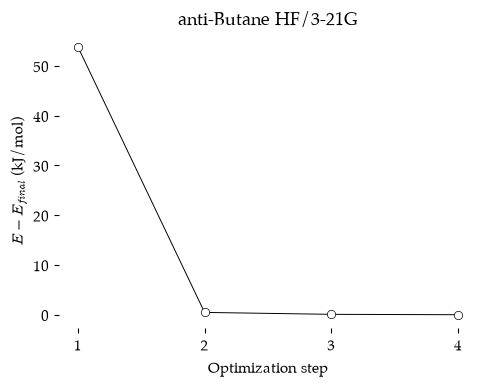

In [21]:
psi4.set_output_file("butane_anti.out", False)

E_anti, hist_anti = psi4.optimize("hf/3-21g", molecule=butane_anti, return_history=True)

print(f"Final energy: {E_anti:.8f} Hartree")
print("Steps taken: ", len(hist_anti["energy"]))
print(f"C4-C1-C2-C3 torsion: {dihedral(butane_anti, 3, 0, 1, 2):.2f} degrees")

show_molecule(butane_anti)
plot_history(hist_anti, "anti-Butane HF/3-21G")

| Line | Notes |
| :---- | :---- |
| `"hf/3-21g"` | Hartree-Fock with the small **3-21G** basis set. This is `GBASIS=N21 NGAUSS=3` in the *GAMESS* input file. Each core orbital is made of 3 Gaussians and each valence orbital is split into parts made of 2 Gaussians and 1 Gaussian. |

The job will **run** and give us the structure with the minimum overall energy. This might be the most stable structure for our molecule. *Psi4* finished in **four** steps with an energy of &minus;156.43246642 Hartree, and the C4&ndash;C1&ndash;C2&ndash;C3 torsion is still 180.00&deg;.

Compare this with the *GAMESS* calculation from the same *Z-matrix* (but with eclipsed methyl groups), which gave &minus;156.4324667 Hartree. The two programs agree to six decimal places (a difference of 3 &times; 10<sup>&minus;7</sup> Hartree). Same method, same basis set, same molecule, same answer. That is reassuring. The *GAMESS* job did not go so smoothly. It ran out of steps after 20 (the `NSTEP=20` setting in the input file) and needed a second run to finish after 28 steps. *Psi4* allows 50 steps by default (the `geom_maxiter` option) and its optimizer, which works in **redundant internal coordinates** (all the bond lengths, angles and torsions, whether we need them or not), took far fewer.

### Are We Done?

*Psi4* told us that the optimization was complete, but let us check the **convergence** table in the output file as we did in the previous chapters.

In [22]:
search_file("butane_anti.out", "~")

   532: 	----------------------------------------------------------------------------------------------~
   533: 	   Step    Total Energy     Delta E     Max Force     RMS Force      Max Disp      RMS Disp   ~
   534: 	----------------------------------------------------------------------------------------------~
   535: 	  Convergence Criteria     1.00e-06 *    3.00e-04 *             o    1.20e-03 *             o~
   536: 	----------------------------------------------------------------------------------------------~
   537: 	     1    -156.41196517   -1.56e+02      3.45e-02      1.39e-02 o    1.03e-01      4.51e-02 o  ~
  1078: 	     2    -156.43229008   -2.03e-02      4.11e-03      1.21e-03 o    1.58e-02      6.81e-03 o  ~
  1618: 	     3    -156.43243762   -1.48e-04      1.65e-03      5.27e-04 o    5.30e-03      1.96e-03 o  ~
  2158: 	     4    -156.43246642   -2.88e-05      2.25e-04 *    5.86e-05 o    7.13e-04 *    1.96e-04 o  ~


At the last step, step 4, the largest force (2.25 &times; 10<sup>&minus;4</sup>) and the largest displacement (7.13 &times; 10<sup>&minus;4</sup>) met their targets (`*`), but the energy change (2.88 &times; 10<sup>&minus;5</sup> Hartree) did **not**. That is enough. *Psi4* declares that it has found a **stationary point** when the largest force is below 3.0 &times; 10<sup>&minus;4</sup> **and either** the change in energy is below 1.0 &times; 10<sup>&minus;6</sup> Hartree **or** the largest displacement is below 1.2 &times; 10<sup>&minus;3</sup>. *GAMESS* used a different test: `OPTTOL=0.0001` requires the largest component of the gradient to be less than 0.0001 Hartree/Bohr and the root-mean-square gradient to be less than one third of that. The two tests are **not** the same, but both are tight enough that the energy is settled to better than 0.01 *kJ/mol*.

### Optimized Structure

*Psi4* reports the final structure at the end of the output file. Since we built the molecule with a *Z-matrix*, it gives us back the *Z-matrix* with the **optimized values** filled in.

In [23]:
with open("butane_anti.out") as f:
    lines = f.readlines()

start = next(i for i, line in enumerate(lines) if "Final optimized geometry" in line)
print("".join(lines[start:start + 20]))

    Final optimized geometry and variables:
    Molecular point group: c1
    Full point group: C2

    Geometry (in Angstrom), charge = 0, multiplicity = 1:

    C       
    C             1    1.540570
    C             2    1.540994      1  112.115256
    C             1    1.540994      2  112.115256      3 -179.999996
    H             1    1.085896      2  109.148493      4 -121.554742
    H             1    1.085896      5  107.219162      2  118.108004
    H             2    1.085896      1  109.148493      3 -121.554742
    H             2    1.085896      7  107.219162      1  118.108004
    H             3    1.084784      2  111.110812      8   58.671265
    H             3    1.085134      9  108.184725      2  121.532494
    H             3    1.085134      9  108.184726     10  116.935011
    H             4    1.084784      1  111.110812      6   58.671265
    H             4    1.085134     12  108.184725      1  121.532494
    H             4    1.085134     12  108.1

Compare each line with the *Z-matrix* that we typed. The first four lines hold the **carbon skeleton**: the C1&ndash;C2 bond is 1.5406 &Aring;, the C2&ndash;C3 and C1&ndash;C4 bonds are 1.5410 &Aring;, the C&ndash;C&ndash;C angles have opened up to 112.12&deg;, and the C4&ndash;C1&ndash;C2&ndash;C3 torsion is 180.00&deg;. The C&ndash;H bonds have shrunk from our generous 1.14 &Aring; to about 1.085 to 1.086 &Aring;.

The fourth line of the *Z-matrix* describes the **torsion** around the central C&ndash;C bond (atoms 1 and 2) as described by the **dihedral angle** between the bonds to the other two carbons. See {numref}`fig5-4` for a diagram describing that coordinate.

```{figure} ../../images/profiles_Picture4.png
---
width: 500px
name: fig5-4
---
*The coordinate describing the central C&ndash;C bond torsion.*
```

The *GAMESS* calculation gave C&ndash;C bonds of 1.5403 &Aring; and 1.5408 &Aring;, a C&ndash;C&ndash;C angle of 112.12&deg; and a torsion of &minus;179.99&deg;. *Psi4* found the same structure. We have found the **structure and energy** of the most stable conformer, the *anti* conformer.

-----

## The Other Conformer

We started the calculation above with a structure that was already *anti* in conformation. It is no surprise that we then **settled** into a bottom of an energy well that describes that situation.

There is another **stable** conformer, the *gauche* conformer. In this conformer the torsion angle should be near 60&deg;. If we set the 4,1,2,3 bond torsion to 60&deg; and then run an optimization calculation, *Psi4* will settle down into the **nearest** energy well, which should be the *gauche* conformer. With our `make_butane()` function, we only have to **change** one number.

Optimizer: Optimization complete!
Final energy: -156.43106157 Hartree
Steps taken:  7
C4-C1-C2-C3 torsion: 60.00 degrees
C-C-C angles: 113.41  113.41 degrees


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

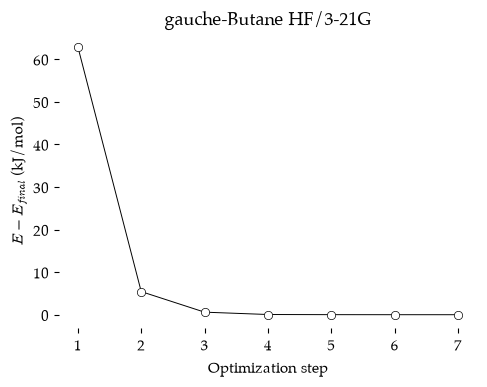

In [24]:
butane_gauche = make_butane(60.0)

psi4.set_output_file("butane_gauche.out", False)

E_gauche, hist_gauche = psi4.optimize("hf/3-21g", molecule=butane_gauche, return_history=True)

print(f"Final energy: {E_gauche:.8f} Hartree")
print("Steps taken: ", len(hist_gauche["energy"]))
print(f"C4-C1-C2-C3 torsion: {dihedral(butane_gauche, 3, 0, 1, 2):.2f} degrees")
print(f"C-C-C angles: {bond_angle(butane_gauche, 2, 1, 0):.2f}  {bond_angle(butane_gauche, 3, 0, 1):.2f} degrees")

show_molecule(butane_gauche)
plot_history(hist_gauche, "gauche-Butane HF/3-21G")

| Line | Notes |
| :---- | :---- |
| `make_butane(60.0)` | A new molecule with a starting torsion of 60&deg;. Everything else is the same. |
| `bond_angle(butane_gauche, 2, 1, 0)` | The C3&ndash;C2&ndash;C1 angle (*Python* numbering). The second angle is C4&ndash;C1&ndash;C2. |

We reached a **final structure** after 8 steps with an energy of &minus;156.43124396 Hartree. The central C&ndash;C torsion is 67.20&deg;. This is very close to the expected value. It is not exactly 60&deg; because of the **steric size** of the methyl group. The two methyl groups push each other apart, and the C&ndash;C&ndash;C angles (both 113.12&deg;) are also larger than in the *anti* conformer.

*GAMESS* found the same conformer after 23 steps, with an energy of &minus;156.4312439 Hartree and a torsion of 67.26&deg;.

## Communicating the Results

We can use *Avogadro* to create **images** of the two results. *Psi4* can write the optimized structures as *xyz* files that *Avogadro* will open.

In [25]:
butane_anti.save_xyz_file("butane_anti.xyz", True)
butane_gauche.save_xyz_file("butane_gauche.xyz", True)

| Line | Notes |
| :---- | :---- |
| `save_xyz_file("butane_anti.xyz", True)` | Writes the molecule in *xyz* format, in &Aring;ngstroms (`True`), to a file beside this notebook. |

Open each file in *Avogadro*. Use the **measure** tool to click on the four carbon atoms in order and the dihedral angle will be displayed. Then choose `File` &rarr; `Export` &rarr; `Graphics` and export the image as PNG. There are many settings here, feel free to explore.

## The Energy

The energy of each **structure** has been calculated. The energy reported is the total electronic energy (plus the repulsion of the nuclei) relative to a world where all the nuclei and electrons are **infinitely far** apart. If a gas of bare nuclei and free electrons came together to form a butane molecule, this is the **energy** that would be released (per molecule). The unit for this energy is Hartrees.

One **Hartree** (*Ha*) is 4.3597 &times; 10<sup>&minus;18</sup> *J*. When we **multiply** by Avogadro's number we get 2625.50 *kJ/mol*.

In [26]:
delta_E = (E_gauche - E_anti) * psi4.constants.hartree2kJmol

print(f"anti:   {E_anti:.8f} Hartree")
print(f"gauche: {E_gauche:.8f} Hartree")
print(f"Difference: {E_gauche - E_anti:.6f} Hartree = {delta_E:.2f} kJ/mol")

anti:   -156.43246642 Hartree
gauche: -156.43106157 Hartree
Difference: 0.001405 Hartree = 3.69 kJ/mol


The **energies** for the final structures in our two calculations are: E = &minus;156.43246642 *Ha* for the *anti* conformer and E = &minus;156.43124396 *Ha* for the *gauche* conformer. The difference is 0.001222 *Ha*. This comes out to 3.21 *kJ/mol* (*GAMESS* gave 3.21 *kJ/mol*). The **literature** value is 3.8 *kJ/mol*, so even this low level of theory (3-21G) performed well.

-----

## Freezing a Coordinate

Allowing the structure to **relax** to minimums at torsional angles of near 180&deg; (*anti*) and 60&deg; (*gauche*) merely requires **allowing** it to happen. But how do we optimize a structure for a maximum? The *syn* conformer and the *eclipsed* conformer are each **peaks** in energy. We can **freeze** the value of any internal coordinate.

In *GAMESS* we listed all 36 internal coordinates in a `$ZMAT` group and then froze the sixth one, the central torsion, with `IFREEZ(1)=6` in the `$STATPT` group. *Psi4*'s optimizer, *optking*, lets us name the coordinate directly by its **atoms**. The option `frozen_dihedral` takes a list of four atom numbers. These are counted from **one**, in the order of the *Z-matrix*, so the central torsion is `"4 1 2 3"`. The value of that **internal coordinate** will not be able to change. All the other bond lengths, angles and torsions will seek their lowest energy so we will hopefully find the lowest energy versions of the *syn* and *eclipsed* conformations.

We will set the 4,1,2,3 torsion to 0&deg; (*syn*) and lock it.

In [27]:
psi4.set_options({"frozen_dihedral": "4 1 2 3"})

butane_syn = make_butane(0.0)

psi4.set_output_file("butane_syn.out", False)

E_syn, hist_syn = psi4.optimize("hf/3-21g", molecule=butane_syn, return_history=True)

print(f"Final energy: {E_syn:.8f} Hartree")
print("Steps taken: ", len(hist_syn["energy"]))
print(f"C4-C1-C2-C3 torsion: {dihedral(butane_syn, 3, 0, 1, 2):.2f} degrees")
print(f"C-C-C angles: {bond_angle(butane_syn, 2, 1, 0):.2f}  {bond_angle(butane_syn, 3, 0, 1):.2f} degrees")

show_molecule(butane_syn)

Optimizer: Optimization complete!
Final energy: -156.42284643 Hartree
Steps taken:  9
C4-C1-C2-C3 torsion: 0.00 degrees
C-C-C angles: 115.89  115.89 degrees


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

| Line | Notes |
| :---- | :---- |
| `psi4.set_options({"frozen_dihedral": "4 1 2 3"})` | **Freezes** the dihedral angle made by atoms 4, 1, 2 and 3 (counting from one) at its **starting** value. This option stays in force for every optimization that follows, until we change it. |
| `make_butane(0.0)` | Starts the torsion at 0&deg;, the *syn* conformation. |

The torsion is still 0.00&deg; at the end of the optimization. It was frozen. The rest of the molecule relaxed over 9 steps. Look at the **C&ndash;C&ndash;C** angles: both 115.89&deg;. The two methyl groups, face to face, have bent away from each other to relieve some of the strain. The energy is &minus;156.42284643 Hartree.

In *GAMESS* this calculation **failed** at first with the error message `UNABLE TO GENERATE PRINCIPAL AXES`. The **zero degree** torsion made the molecule so symmetrical that *GAMESS* could not decide how to line it up with the *x*, *y* and *z* axes. I had to **mess up** the symmetry of the input file by changing a few of the 120&deg; values to 119&deg;. *Psi4* had no such trouble. When it did work, *GAMESS* gave an energy of &minus;156.4228465 Hartree after 23 steps.

I then set the **torsion angle** to 120&deg; (*eclipsed*) and ran the calculation again. The `frozen_dihedral` option is still set, so we only need a new molecule.

In [28]:
butane_eclipsed = make_butane(120.0)

psi4.set_output_file("butane_eclipsed.out", False)

E_eclipsed, hist_eclipsed = psi4.optimize("hf/3-21g", molecule=butane_eclipsed, return_history=True)

print(f"Final energy: {E_eclipsed:.8f} Hartree")
print("Steps taken: ", len(hist_eclipsed["energy"]))
print(f"C4-C1-C2-C3 torsion: {dihedral(butane_eclipsed, 3, 0, 1, 2):.2f} degrees")

show_molecule(butane_eclipsed)

Optimizer: Optimization complete!
Final energy: -156.42672629 Hartree
Steps taken:  5
C4-C1-C2-C3 torsion: 120.00 degrees


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

The reported energy for the structure with the C&ndash;C torsion frozen at 120.00&deg; was &minus;156.42672629 Hartree after 5 steps (*GAMESS*: &minus;156.4267264 Hartree after 26 steps).

```{warning}
The `frozen_dihedral` option is **still set**. Every optimization that we run from now on in this notebook will freeze the 4,1,2,3 torsion. To go back to a normal optimization, clear all the options with `psi4.core.clean_options()` and then set `scf_type` again.
```

-----

## The Energy Profile

We now have points for **all four** identified conformers. If we use the *anti* conformer as the base, we can calculate the difference in energy to the two maximums. We will collect the results in a table and save them as a JSON file.

In [29]:
conformers = pd.DataFrame({
    "Conformer": ["syn", "gauche", "eclipsed", "anti"],
    "Torsion (deg)": [dihedral(butane_syn, 3, 0, 1, 2), dihedral(butane_gauche, 3, 0, 1, 2),
                      dihedral(butane_eclipsed, 3, 0, 1, 2), abs(dihedral(butane_anti, 3, 0, 1, 2))],
    "Energy (Eh)": [E_syn, E_gauche, E_eclipsed, E_anti],
    "Steps": [len(hist_syn["energy"]), len(hist_gauche["energy"]),
              len(hist_eclipsed["energy"]), len(hist_anti["energy"])],
})
conformers["Delta E (kJ/mol)"] = (conformers["Energy (Eh)"] - E_anti) * psi4.constants.hartree2kJmol

conformers.to_json("butane_conformers_HF321G.json", orient="records", indent=2)
conformers.round(4)

,Conformer,Torsion (deg),Energy (Eh),Steps,Delta E (kJ/mol)
0,syn,0.0,-156.4228,9,25.2573
1,gauche,60.0,-156.4311,7,3.6884
2,eclipsed,120.0,-156.4267,5,15.0707
3,anti,180.0,-156.4325,4,0.0000


| Line | Notes |
| :---- | :---- |
| `abs(dihedral(...))` | The *anti* torsion could come out as +180&deg; or &minus;180&deg; (the same thing). `abs()` makes it positive so the points line up from 0&deg; to 180&deg;. |
| `conformers["Delta E (kJ/mol)"] = ...` | Adds a **new column**: each energy minus the *anti* energy, converted to *kJ/mol*. *Pandas* does the subtraction for every row at once. |

We calculate that the *syn* conformer is 25.26 *kJ/mol* higher in energy than the *anti* conformer and the *eclipsed* conformer is 15.07 *kJ/mol* higher (*GAMESS*: 25.3 and 15.2 *kJ/mol*).

We could use this information to **sketch** out the rotational energy profile. The dotted line in the plot below is just drawn in and has no mathematical value, although it's likely close to how the energy changes with torsion angle. Remember, we are using a low level of theory and are in **gas phase**, so accuracy will be low but the trend is clear.

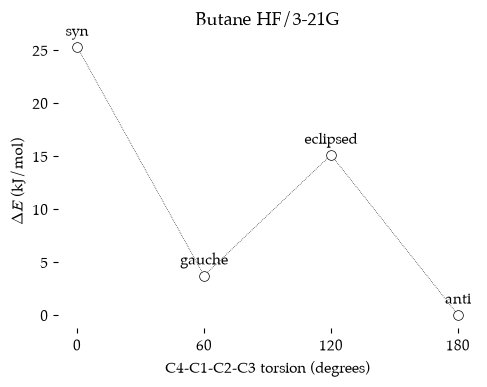

In [30]:
x = conformers["Torsion (deg)"]
y = conformers["Delta E (kJ/mol)"]

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4))
ax.plot(x, y, color="black", linewidth=0.5, linestyle=":", zorder=1)
ax.plot(x, y, linestyle="none", marker="o", markersize=7, markerfacecolor="white",
        markeredgecolor="black", markeredgewidth=0.5, zorder=2)
for name, xi, yi in zip(conformers["Conformer"], x, y):
    ax.annotate(name, (xi, yi), textcoords="offset points", xytext=(0, 8), ha="center")
ax.set_xticks([0, 60, 120, 180])
ax.set_xlabel("C4-C1-C2-C3 torsion (degrees)")
ax.set_ylabel(r"$\Delta E$ (kJ/mol)")
ax.set_title("Butane HF/3-21G")
plt.show()

| Line | Notes |
| :---- | :---- |
| `linestyle=":"` | A thin **dotted** line joining the points, drawn underneath them (`zorder=1`). It is only a guide for the eye. |
| `ax.annotate(name, (xi, yi), ...)` | Writes the name of each conformer 8 points **above** its data point. `zip()` walks through the three lists together. |

The four conformers sketch out the familiar shape: a big hill at the *syn* conformation, a valley at *gauche*, a smaller hill at the *eclipsed* conformation and the deepest valley at *anti*.

We can **repeat** these calculations again and again using **different values** for the 4,1,2,3 torsion. All it takes is typing and time. In the [next section](052-Workflow.ipynb) we will let a *Python* **loop** do the typing for us and calculate the energy every 10&deg; from 0&deg; to 180&deg;.

-----

## Following an Optimization

*Psi4* gave us the energy at each step of each optimization in the history dictionary. It also gave us the **gradient** at each step: the slope of the energy with respect to each *x*, *y* and *z* coordinate of each atom. Let us look at the journey taken by the *gauche* optimization. First, the energy at each step can be found in the output file, just like we found it for water. (In *GAMESS* we used the *Unix* tool *grep* to pull the `NSERCH` lines out of the log file.)

In [31]:
search_file("butane_gauche.out", "@RHF Final Energy")

   232:   @RHF Final Energy:  -156.40710550963385
   773:   @RHF Final Energy:  -156.42899402647404
  1314:   @RHF Final Energy:  -156.43083314945045
  1854:   @RHF Final Energy:  -156.43104340343240
  2394:   @RHF Final Energy:  -156.43105649635669
  2933:   @RHF Final Energy:  -156.43106060702070
  3471:   @RHF Final Energy:  -156.43106156638189


One line for **each step** of the optimization. Now let us plot both the energy and the largest component of the gradient at each step from the `hist_gauche` dictionary.

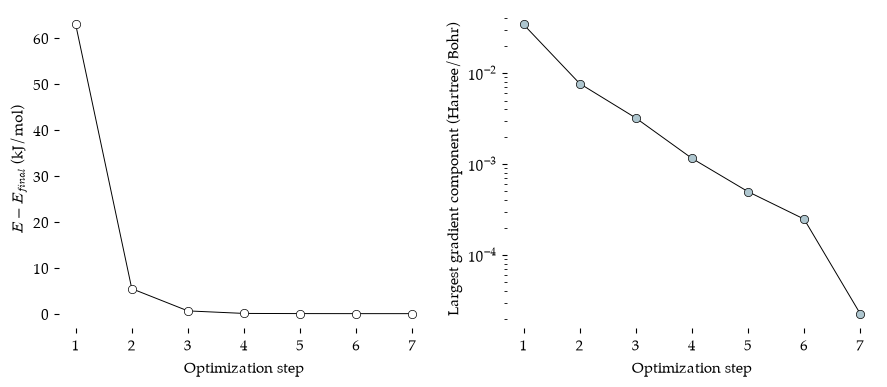

Largest gradient component at each step:
[ 0.03434800  0.00769500  0.00321800  0.00115800  0.00049800  0.00024800
  0.00002300]


In [32]:
energies = np.array(hist_gauche["energy"])
delta_E = (energies - energies[-1]) * psi4.constants.hartree2kJmol
max_grad = [np.max(np.abs(g)) for g in hist_gauche["gradient"]]
steps = np.arange(1, len(energies) + 1)

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(9,4))

axs[0].plot(steps, delta_E, color="black", linewidth=0.7, marker="o",
            markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5)
axs[0].set_xlabel("Optimization step")
axs[0].set_ylabel(r"$E - E_{final}$ (kJ/mol)")

axs[1].plot(steps, max_grad, color="black", linewidth=0.7, marker="o",
            markerfacecolor="#AEC6CF", markeredgecolor="black", markeredgewidth=0.5)
axs[1].set_yscale("log")
axs[1].set_xlabel("Optimization step")
axs[1].set_ylabel("Largest gradient component (Hartree/Bohr)")

plt.show()

print("Largest gradient component at each step:")
print(np.round(max_grad, 6))

| Line | Notes |
| :---- | :---- |
| `hist_gauche["gradient"]` | A list with one item per step. Each item is the **gradient** for that structure: 42 numbers (14 atoms &times; 3 coordinates) in Hartree/Bohr. |
| `[np.max(np.abs(g)) for g in ...]` | For each step, the largest gradient component, ignoring its sign. This is like the `GRAD. MAX` value on the *GAMESS* `NSERCH` lines. |
| `axs[1].set_yscale("log")` | A **logarithmic** axis. The gradient falls by orders of magnitude, and on a linear axis the last few points would all sit on the floor. |

The energy **changes** quickly in the first few steps and then we keep making small changes until *Psi4* halted the optimization. The energy fell by 63 *kJ/mol* in the first step and was within 1 *kJ/mol* of the final value by step 3. The gradient fell more slowly, until it suddenly dropped by a factor of ten between steps 6 and 7. There was one phase where the process found a **steeper** path to the finish line. It's like going down a ski hill. You will always follow the **steepest** line from where you are standing, not always the best line. And you will encounter trees occasionally.

The largest gradient component fell from 0.0343 to 1.8 &times; 10<sup>&minus;5</sup> Hartree/Bohr. In *GAMESS* this optimization took 23 steps (19 steps in a second run) and the plots were made by extracting the `NSERCH` lines with *grep*, cleaning them up and loading them into a spreadsheet. Here, the numbers were already **waiting** in a *Python* variable.

## Summary

We **built** a model of butane using a *Z-matrix* in a *Python* function and **optimized** the structure for the *anti* conformation and found the *gauche* conformation by starting with an initial structure that was **near** that conformation. Thus we located the **global** minimum and a **local** minimum on the **rotational energy surface**. Our energies matched those from *GAMESS* closely.

Then we used the `frozen_dihedral` option to **freeze** the coordinate that corresponded to the central C&ndash;C **bond rotation**, and set the internal coordinate for that **torsion** to 0&deg; and 120&deg; to find the energy of the *syn* conformation and an *eclipsed* conformation. With this, we have the important parts of the rotational energy profile.

We examined the **format** of the *Z-matrix* in detail and saw that a bad start (eclipsed methyl groups) can leave us stranded on a hilltop. We used the optimization **history** to plot the energy and the gradient at each step without searching through any files. In the [next section](052-Workflow.ipynb) we will use the *Z-matrix* and a *Python* loop to calculate the complete rotational energy profile.

## Exercise

Read the accompanying discussion and then try the following exercises.

### The Activities

**Construct** ethane, propane, butane and 2-methylbutane as *Z-matrices* in *Python* functions that take the central C&ndash;C torsion angle as their argument.

**Identify** all likely minima and maxima along the **rotational energy surface** using the central C&ndash;C torsion coordinate of each molecule. **Calculate** the HF/3-21G energy for optimized structures at these points in the coordinate. Use frozen coordinates (or symmetry) for the energy maxima. **Create** a table with the energies and torsion angles for all your calculations (relative to the global minimum in each) with units in *kJ/mol* and degrees.

Using a *Python* loop (see the [next section](052-Workflow.ipynb)), or brute force, **calculate** rotational energy scans of these molecules. Produce a **plot** of energy vs. angle to create a **visual representation** of the rotational energy profile of each molecule. Try placing all four profiles on the same plot for comparison.

**Going further:** Change lines 9 and 12 of the butane *Z-matrix* back to 0&deg; (eclipsed methyl groups, as in the *GAMESS* book) and optimize the *anti* conformer. Compare the energy and the H9&ndash;C3&ndash;C2&ndash;H8 torsion (`dihedral(mol, 8, 2, 1, 7)`) with our result. What happened? Now change one of those angles to 1&deg; and try again.

````{admonition} Hint: freezing and un-freezing
:class: dropdown
Options in *Psi4* stay set until you change them. When you move from an unconstrained optimization (a minimum) to a constrained one (a maximum) and back, clear the options and set them again.

```python
psi4.core.clean_options()
psi4.set_options({"scf_type": "pk"})                               # minimum
psi4.set_options({"scf_type": "pk", "frozen_dihedral": "4 1 2 3"}) # maximum
```

Make sure that the four atom numbers in `frozen_dihedral` match the **torsion** line of *your* *Z-matrix*. They count from one.
````

````{admonition} Hint: timing a calculation
:class: dropdown
*Python* can time anything.

```python
import time
start = time.time()
psi4.optimize("hf/3-21g", molecule=mol)
print(f"{time.time() - start:.1f} seconds")
```
````

### The Report

Present a ONE PAGE **document** with the table of angles and energies for maxima and minima that you generated. Include the plot of the entire rotational energy profile and **comment** if it fits with your table.

Please **report the time** it took to set up and run the calculations and to extract the energy data from the results. The table and plot must be professional in appearance.

```{warning} AI Statement
:class: dropdown
This page is an adaptation of the "Rotation Profiles" chapter of my [previous web book on using *GAMESS*](https://blinkletter.github.io/UsingGAMESS). About **forty percent** of the text is **my own work**, carried over word for word or lightly edited. This includes the introduction and learning goals, the line-by-line construction of the *Z-matrix*, the discussion of the *anti* and *gauche* conformers, the energy units, freezing a coordinate, the energy profile, the ski hill, and the exercise and report. The figures of the *Z-matrix* are also mine, from the previous book. The **rest of the page** was written by an **LLM system** at my request. I asked it to convert the *GAMESS* jobs to *Python* code for *Psi4* at the HF/3-21G level, to replace the *MacMolPlt* and *Unix* sections with *Python*, and to compare the results with the *GAMESS* calculations. All of the *Python* code, the line-by-line explanations of it, the discussion of the eclipsed methyl groups, the analysis of the output files and the commentary on the results were written by the LLM. I ran every calculation on my own computer, and the numbers quoted in the text come from those results.
```